# Laboratorio de Aprendizaje Automático - Parte 2

## Inteligencia Artificial - DCIC, UNS (2026)

En este laboratorio aprenderemos conceptos y herramientas para el desarrollo de un proyecto con técnicas de aprendizaje automático. Veremos algunas nociones para el preprocesamiento de datos, junto con la construcción, entrenamiento y generación de predicciones utilizando dos métodos de aprendizaje automático: Árboles de Decisión (AD) y Redes Neuronales Artificiales (RNA).

**Recuerde hacer una copia de este notebook en su drive**.

## Plan de Trabajo

En esta segunda parte, nos vamos a enfocar en el desarrollo de árboles de decisión (AD) usando las funcionalidades provistas por la librería scikit-learn.

En particular, vamos a construir un AD para abordar un problema de clasificación y usarlo para generar nuevas predicciones.

## Datasets

En el laboratorio vamos a utilizar tres datasets, que pueden **descargar ejecutando la primera celda de código** o desde el siguiente enlace: [datasets](https://www.dropbox.com/scl/fi/p7f6v2wrtvlptzt9adkm8/datasets_laboratorio.zip?rlkey=o4x7m6mmgkf1fxgc13as16gb7&dl=0).

*   Titanic dataset (titanic.csv)
*   Dataset precio celulares (cellphones.csv)
*   Dataset géneros musicales (music.csv)

## Librerías

A lo largo del laboratorio se usan principalmente tres librerías:
*   **Pandas**: Permite utilizar y analizar los datos. Link: https://pandas.pydata.org/docs/
*   **Scikit-learn**: Permite manipular los datos e implementar diversos algoritmos de *Machine Learning*. Link: https://scikit-learn.org/stable/
*   **Keras**: Permite implementar Redes Neuronales Artificiales de manera intuitiva. Link: https://keras.io/getting_started/

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os
import warnings
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'
warnings.filterwarnings("ignore")

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, classification_report
from sklearn.preprocessing import MinMaxScaler
from sklearn.preprocessing import OneHotEncoder

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras.utils import to_categorical
from tensorflow.keras import Sequential, layers, Input

# Ejecutar para descargar y extraer los datasets.
!pip install -q gdown
!gdown --fuzzy "https://drive.google.com/file/d/16AB3ixX9q2S7fHAbiE7id7zj1fCgPbo4/view" -O /content/datasets_laboratorio.zip
!unzip -o /content/datasets_laboratorio.zip -d /content/

Downloading...
From: https://drive.google.com/uc?id=16AB3ixX9q2S7fHAbiE7id7zj1fCgPbo4
To: /content/datasets_laboratorio.zip
100% 155k/155k [00:00<00:00, 25.9MB/s]
Archive:  /content/datasets_laboratorio.zip
  inflating: /content/music.csv      
  inflating: /content/titanic.csv    
  inflating: /content/cellphones.csv  


## Clasificación usando Árbol de Decisión

El aprendizaje basado en **Árboles de Decisión** es una de las técnicas de aprendizaje supervisado más populares, debido a su simplicidad, facilidad de interpretación y de implementación. El algoritmo permite representar las instancias de un conjunto de datos relacionando sus atributos y la etiqueta que marca la clasificación correcta de cada instancia.

Un árbol de decisión tiene las siguientes características:

*   Los **nodos internos** se etiquetan con atributos que caracterizan a las instancias.
*   Los **arcos** salientes de un nodo etiquetado con un atributo A se etiquetan con cada valor posible de A.
*   Las **hojas** marcan una decisión o etiqueta de respuesta.

En las celdas siguientes vamos a contruir un árbol de decisión usando la librería *scikit-learn*. Esta implementación de la librería, que se llama `DecisionTreeClassifier`, sólo permite atributos numéricos (las etiquetas pueden ser strings).

El objetivo será desarrollar un clasificador para predecir el rango de precio de un celular, considerando algunos atributos del dispositivo.

**Links**:
* `https://scikit-learn.org/stable/modules/generated/sklearn.tree.DecisionTreeClassifier.html`
* `https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.train_test_split.html`

### Carga y separación de los datos

In [ ]:
# Cargar el dataset
df_cellphones = pd.read_csv('/content/cellphones.csv')

print(f"Cantidad de ejemplos: {df_cellphones.shape[0]} \nCantidad de columnas: {df_cellphones.shape[1]} \n")
df_cellphones.head(5)

Cantidad de ejemplos: 400 
Cantidad de columnas: 6 



,ram,battery_power,px_height,px_width,wifi,price_range
0,435,1702,921,1351,1,A
1,3271,1722,865,1741,1,D
2,2378,504,1207,1539,0,C
3,3746,591,892,1603,0,D
4,402,1794,43,627,1,A


In [ ]:
df_cellphones.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 400 entries, 0 to 399
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   ram            400 non-null    int64 
 1   battery_power  400 non-null    int64 
 2   px_height      400 non-null    int64 
 3   px_width       400 non-null    int64 
 4   wifi           400 non-null    int64 
 5   price_range    400 non-null    object
dtypes: int64(5), object(1)
memory usage: 18.9+ KB


### Separar columna *target*

In [ ]:
# Valores de la columna target.
Y = df_cellphones['price_range'].values

# Porción del dataframe con los atributos.
X = df_cellphones.drop(columns = ["price_range"])

In [ ]:
Y

array(['A', 'D', 'C', 'D', 'A', 'C', 'B', 'D', 'D', 'B', 'B', 'D', 'A',
       'B', 'B', 'A', 'B', 'C', 'A', 'D', 'D', 'D', 'D', 'D', 'C', 'C',
       'A', 'A', 'A', 'B', 'D', 'C', 'A', 'C', 'A', 'C', 'D', 'B', 'D',
       'A', 'B', 'A', 'A', 'A', 'A', 'A', 'C', 'D', 'C', 'A', 'C', 'C',
       'A', 'D', 'C', 'D', 'B', 'D', 'C', 'A', 'B', 'D', 'A', 'D', 'D',
       'A', 'B', 'C', 'A', 'A', 'C', 'C', 'B', 'B', 'D', 'C', 'D', 'D',
       'A', 'B', 'A', 'B', 'D', 'B', 'C', 'C', 'C', 'C', 'A', 'B', 'B',
       'B', 'C', 'C', 'A', 'B', 'A', 'A', 'D', 'D', 'B', 'C', 'D', 'A',
       'A', 'B', 'C', 'B', 'C', 'C', 'B', 'A', 'B', 'B', 'D', 'B', 'A',
       'A', 'C', 'A', 'B', 'D', 'C', 'D', 'C', 'D', 'C', 'B', 'D', 'B',
       'D', 'A', 'B', 'C', 'C', 'C', 'A', 'C', 'A', 'B', 'B', 'C', 'C',
       'A', 'C', 'B', 'D', 'C', 'D', 'A', 'C', 'C', 'B', 'C', 'B', 'D',
       'A', 'D', 'B', 'B', 'A', 'A', 'D', 'C', 'B', 'B', 'D', 'A', 'B',
       'B', 'D', 'B', 'C', 'B', 'C', 'A', 'C', 'A', 'C', 'C', 'D

In [ ]:
X

,ram,battery_power,px_height,px_width,wifi
0,435,1702,921,1351,1
1,3271,1722,865,1741,1
2,2378,504,1207,1539,0
3,3746,591,892,1603,0
4,402,1794,43,627,1
...,...,...,...,...,...
395,3791,1313,416,1308,1
396,3709,1038,4,638,1
397,1424,618,591,724,0
398,1228,1329,1053,1458,1


### Desarrollo de Árbol de Decisión

La implementación de la librería nos permite configurar distintos parámetros del modelo. Por ejemplo, podemos configurar la profundidad máxima que debe tener el árbol (`max_depth`), el criterio con el cual se elige el próximo atributo en un nodo interno (`criterion`), la cantidad mínima de instances debe haber para generar un nodo interno (`min_samples_split`), entre otros.

Vamos a experimentar con uno solo de estos parámetros, la profundidad máxima. Comencemos creando un árbol de decisión de profundidad 1.

In [ ]:
# Creamos un árbol de decisión (AD)
clf = DecisionTreeClassifier(max_depth = 1)

# Se ajusta el AD con los datos de entrenamiento
clf = clf.fit(X, Y)

print(f"¿Qué profundidad tiene el árbol creado?\n{clf.get_depth()}\n")

print(f"¿Cuántas hojas tiene el árbol?\n{clf.get_n_leaves()}\n")

print(f"¿Cuántos de los atributos fueron usados?\n{clf.n_features_in_}\n")

print(f"¿Cuántos atributos eran en total?\n{len(X.columns.values)}\n")

# Obtener predicciones
predictions = clf.predict(X)

print('Algunas predicciones del AD: ', predictions[:10])

¿Qué profundidad tiene el árbol creado?
1

¿Cuántas hojas tiene el árbol?
2

¿Cuántos de los atributos fueron usados?
5

¿Cuántos atributos eran en total?
5

Algunas predicciones del AD:  ['A' 'D' 'D' 'D' 'A' 'A' 'A' 'D' 'D' 'A']


In [ ]:
print("Reporte de clasificación\n")
print(classification_report(Y, predictions))

Reporte de clasificación

              precision    recall  f1-score   support

           A       0.47      1.00      0.64       100
           B       0.00      0.00      0.00       100
           C       0.00      0.00      0.00       100
           D       0.53      1.00      0.69       100

    accuracy                           0.50       400
   macro avg       0.25      0.50      0.33       400
weighted avg       0.25      0.50      0.33       400



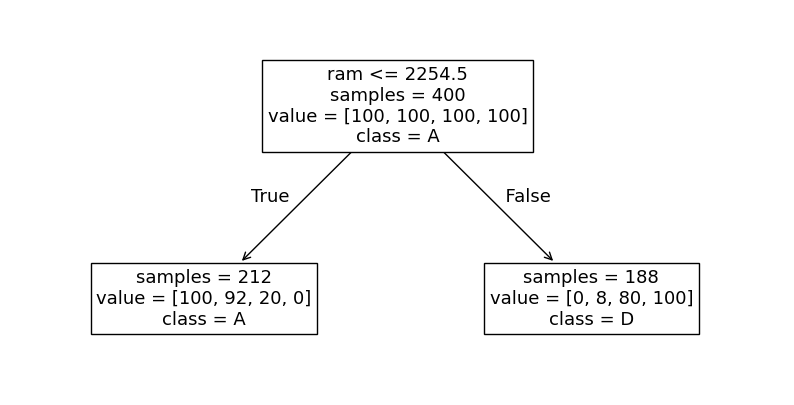

In [ ]:
# Gráfico del árbol
feature_names = X.columns.values.tolist()
fig, ax = plt.subplots(figsize = (10, 5))
plot_tree(clf, max_depth = 1, fontsize = 13, feature_names = feature_names, class_names = clf.classes_, impurity = False)
plt.show()

### Separar un conjunto de validación

In [ ]:
# Porcentajes para datos de validación y test.
test_size = 0.15
val_size = 0.10

# La función train_test_split separa los datos (X, Y) en dos porciones
X_train, X_test, y_train, y_test = train_test_split(X, Y, test_size = test_size, random_state = 10)
X_train, X_val, y_train, y_val = train_test_split(X_train, y_train, test_size = val_size, random_state = 10)

# Nos guardamos los nombres de los atributos para más adelante
feature_names = X_train.columns.values[:-1]

print("Datos de entrenamiento:\n\tCantidad de ejemplos (filas): {}\n\tCantidad de atributos (columnas): {}\n".format(X_train.shape[0], X_train.shape[1]))
print("Datos de validación:\n\tCantidad de ejemplos (filas): {}\n\tCantidad de atributos (columnas): {}\n".format(X_val.shape[0], X_val.shape[1]))
print("Datos de test:\n\tCantidad de ejemplos (filas): {}\n\tCantidad de atributos (columnas): {}".format(X_test.shape[0], X_test.shape[1]))

In [ ]:
# Crear un árbol de decisión (AD) de profundidad 1 usando solo los datos de entrenamiento.
clf = DecisionTreeClassifier(max_depth = 1)
clf = clf.fit(X_train, y_train)

# Información sobre el AD aprendido
print("Profundidad del árbol: {}".format(clf.get_depth()))
print("Cantidad de nodos (internos + hojas): {}".format(clf.tree_.node_count))
print("Cantidad de hojas: {}".format(clf.get_n_leaves()))


In [ ]:
#Crear una copia de X_test que incorpore dos nuevas columnas: (1) con los valores de y_test y (2) con los valores predichos por clf.
#Mostrar algunos ejemplos del nuevo dataframe.

df_test = X_test.copy()

df_test["targett"] = y_test

y_pred = clf.predict(X_test)

df_test["prediction"] = y_pred

df_test.head(10)


In [ ]:
#Mostramos el Accuracy sobre el conjunto de entrenamiento:
print("Accuracy sobre conjunto de train:", clf.score(X_train, y_train))

print("Accuracy sobre conjunto de test:", clf.score(X_test, y_test))
# print("Accuracy sobre conjunto de test:", accuracy_score(y_test, predictions))

#La comparación de estos dos valores pueden darnos indicions de overfitting (sobreajuste) o underfitting (subajuste).

In [ ]:
# Lista de profundidades con valores enteros.
profundidades = [1, 5, 10, 20, 30, 50] # Esta lista puede modificarse, cambiando valores y/o agregando otros.

# Construir árboles de decisión con distintos valores para el parámetro profundidad y evaluar, usando accuracy, cuál de ellos es mejor.
# <TO-DO>

# Porcentajes para datos de validación y test.
test_size = 0.15
val_size = 0.10

# La función train_test_split separa los datos (X, Y) en dos porciones
X_train, X_test, y_train, y_test = train_test_split(X, Y, test_size = test_size, random_state = 10)
X_train, X_val, y_train, y_val = train_test_split(X_train, y_train, test_size = val_size, random_state = 10)

# Nos guardamos los nombres de los atributos para más adelante
feature_names = X_train.columns.values[:-1]

mejor_profundidad = 10

for profundidad in profundidades:
  # Crear un árbol de decisión (AD) de profundidad 1 usando solo los datos de entrenamiento.
  clf = DecisionTreeClassifier(max_depth = profundidad, random_state=10)
  clf = clf.fit(X_train, y_train)

  #Mostramos el Accuracy sobre el conjunto de entrenamiento:
  print(f"***Profundidad: {profundidad}")
  print("Accuracy sobre conjunto de train:", clf.score(X_train, y_train))
  print("Accuracy sobre conjunto de validacion:", clf.score(X_val, y_val))
  #print("Accuracy sobre conjunto de test:", clf.score(X_test, y_test))

  # Agregar target y prediction a una copia de X_test
  df_test = X_test.copy()
  df_test["target"] = y_test
  y_pred = clf.predict(X_test)
  df_test["prediction"] = y_pred

  #print()
  #print(df_test.head(10))
  print()






In [ ]:
# Creamos AD con profundidad máxima MAX
clf = DecisionTreeClassifier(max_depth = mejor_profundidad)

# Ajustamos el AD con los datos de entrenamiento
clf = clf.fit(X_train, y_train)

# Información sobre el AD aprendido
print("Profundidad del árbol: {}".format(clf.get_depth()))
print("Cantidad de nodos (internos + hojas): {}".format(clf.tree_.node_count))
print("Cantidad de hojas: {} \n".format(clf.get_n_leaves()))

# Predicciones sobre el conjunto de test
predictions = clf.predict(X_test)

print("Accuracy sobre el conjunto de test:", round(accuracy_score(y_test, predictions), 2), "\n")

print("Reporte de clasificación\n", classification_report(y_test, predictions))

In [ ]:
# Gráfico del árbol
fig, ax = plt.subplots(figsize = (30, 10))
plot_tree(clf, max_depth = mejor_profundidad, fontsize = 10, feature_names = feature_names, class_names = clf.classes_, impurity = False)
plt.show()

### Probemos otros parámetros para el modelo.

In [ ]:
# Desarrollar un nuevo árbol de decisión para predecir el rango de precio de un celular, pero esta vez utilizando al menos dos parámetros (distintos de max_depth) configurables del modelo.
# <TO-DO>